# Neural PDE Exercises · 04
## Energy and weak residuals

**Course section:** Variational and weak methods. **Time:** 35–50 minutes.
This notebook is self-contained: select **Restart Kernel and Run All Cells** in a
fresh Python 3.11+ kernel. CPU / float64; the supplied run is a working baseline.

[All practical exercises](README.md) · [Laboratory guide](../NOTEBOOK_README.md) ·
[Related laboratory](../Neural_PDE_01_foundations.ipynb)

**How to work:** predict the outcome, run the baseline, then edit the marked
settings and rerun all cells. Keep a small results table and answer the reflection
questions. Use the same seed and training budget when comparing methods.

**Notation:** $u$ is the reference state, $u_\theta$ the neural state,
$r_\theta=\mathcal L u_\theta-f$, $\widehat{\mathcal J}$ a sampled loss,
and $\mathcal E$ an energy. Reference values are used for checking errors after
training, except when observations are explicitly supplied.

## 1 · Predict before computing

For $-u''=f=\pi^2\sin(\pi x)$ with zero endpoint values, train identical hard-boundary
networks with two first-derivative formulations:
$$\mathcal E(v)=\int_0^1\left(\tfrac12|v'|^2-fv\right)\,dx,$$
$$R_k(v)=\int_0^1(v'\phi_k'-f\phi_k)\,dx,\qquad
\phi_k(x)=\sin(k\pi x),\qquad
\widehat{\mathcal J}_{\mathrm{weak}}=\frac1K\sum_{k=1}^K
\left|\widehat R_k/(k\pi)\right|^2.$$

Gauss–Legendre nodes approximate the integrals. The energies and squared moments
have different meanings and scales; compare errors on the same independent grid.
**Predict:** can a finite test space miss some errors?

In [1]:
import copy
import math
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 7
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                 ["teal", "orange", "pink", "blue", "navy"]]),
})

def network(width=20, activation=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

class State(nn.Module):
    def __init__(self, initial, hard=True):
        super().__init__()
        self.net, self.hard = copy.deepcopy(initial), hard
    def forward(self, x):
        raw = self.net(x)
        return x*(1-x)*raw if self.hard else raw

def derivative(value, x):
    return torch.autograd.grad(value.sum(), x, create_graph=True)[0]

def forcing(x):
    return math.pi**2 * torch.sin(math.pi*x)

def residual(model, points):
    x = points.detach().clone().requires_grad_(True)
    u = model(x)
    return -derivative(derivative(u, x), x) - forcing(x)

def train(model, objective, steps=500, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    started = time.perf_counter()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(model)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    assert np.isfinite(history).all(), "The optimizer produced a non-finite objective."
    return np.asarray(history), time.perf_counter()-started

# This independent grid is never passed to a training objective.
check_x = torch.linspace(0, 1, 503).reshape(-1, 1)
check_u = torch.sin(math.pi*check_x).numpy().ravel()
boundary_x = torch.tensor([[0.0], [1.0]])

def diagnostics(model):
    with torch.no_grad():
        prediction = model(check_x).numpy().ravel()
        boundary_error = float(model(boundary_x).abs().max())
    scaled_residual = residual(model, check_x).detach().numpy().ravel()/math.pi**2
    relative_l2 = np.linalg.norm(prediction-check_u)/np.linalg.norm(check_u)
    return {"prediction": prediction, "relative_l2": float(relative_l2),
            "residual_rms": float(np.sqrt(np.mean(scaled_residual**2))),
            "boundary_max": boundary_error}

print(f"CPU / float64 / seed {SEED} / PyTorch {torch.__version__}")

CPU / float64 / seed 7 / PyTorch 2.10.0


Deep Ritz    | final objective -2.4673e+00 | relative L2 8.202e-04 | residual RMS 3.330e-02


Weak moments | final objective  7.3276e-06 | relative L2 1.268e-03 | residual RMS 5.068e-02
Exact solution energy: -2.467401


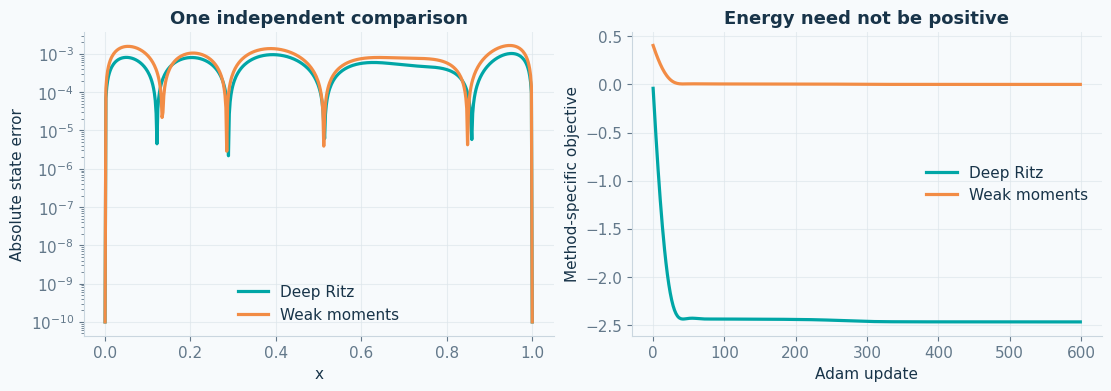

In [2]:
# EDIT HERE: test the number of moments separately from quadrature resolution.
N_QUADRATURE = 64
N_TESTS = 6
STEPS = 600
nodes, weights = np.polynomial.legendre.leggauss(N_QUADRATURE)
qx = torch.tensor(((nodes+1)/2)[:, None])
qw = torch.tensor((weights/2)[:, None])
frequencies = math.pi*torch.arange(1, N_TESTS+1).reshape(1, -1)
phi = torch.sin(qx*frequencies)
dphi = frequencies*torch.cos(qx*frequencies)
initial = network()

def energy(candidate):
    x = qx.detach().clone().requires_grad_(True)
    value = candidate(x)
    return (qw*(0.5*derivative(value, x).square()-forcing(x)*value)).sum()

def weak_loss(candidate):
    x = qx.detach().clone().requires_grad_(True)
    value = candidate(x)
    moments = (qw*(derivative(value, x)*dphi-forcing(x)*phi)).sum(dim=0)
    return (moments/frequencies.ravel()).square().mean()

reports, histories = {}, {}
for name, objective in [("Deep Ritz", energy), ("Weak moments", weak_loss)]:
    model = State(initial)
    history, seconds = train(model, objective, STEPS)
    report = diagnostics(model)
    reports[name], histories[name] = report, history
    print(f"{name:12s} | final objective {float(objective(model).detach()): .4e} | "
          f"relative L2 {report['relative_l2']:.3e} | residual RMS {report['residual_rms']:.3e}")
print(f"Exact solution energy: {-math.pi**2/4:.6f}")
assert abs(float(qw.sum())-1.0) < 1e-12
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for name, report in reports.items():
    axes[0].semilogy(check_x, np.maximum(np.abs(report["prediction"]-check_u), 1e-10), label=name)
    axes[1].plot(histories[name], label=name)
axes[0].set(title="One independent comparison", xlabel="x", ylabel="Absolute state error")
axes[1].set(title="Energy need not be positive", xlabel="Adam update", ylabel="Method-specific objective")
for ax in axes:
    ax.grid(); ax.legend()
plt.show()

## 2 · A finite test space has a nullspace

With tests $k=1,\ldots,K$, the perturbation $\varepsilon\sin((K+1)\pi x)$ is orthogonal
to the tests in the weak derivative pairing. Compute its moments with finer
quadrature, independently of the quadrature used for training.

In [3]:
probe_nodes, probe_weights = np.polynomial.legendre.leggauss(max(128, 8*(N_TESTS+1)))
probe_x = (probe_nodes+1)/2
probe_w = probe_weights/2
HIDDEN_AMPLITUDE = 0.1
hidden_mode = N_TESTS+1
hidden_derivative = HIDDEN_AMPLITUDE*hidden_mode*np.pi*np.cos(hidden_mode*np.pi*probe_x)
missed_moments = np.array([
    np.sum(probe_w*hidden_derivative*k*np.pi*np.cos(k*np.pi*probe_x))
    for k in range(1, N_TESTS+1)])
print("Largest perturbation moment in the test space:", np.max(np.abs(missed_moments)))
print("Exact relative L2 perturbation:", abs(HIDDEN_AMPLITUDE))
print("Exact scaled residual RMS:", abs(HIDDEN_AMPLITUDE)*hidden_mode**2/np.sqrt(2))
assert np.max(np.abs(missed_moments)) < 1e-8

Largest perturbation moment in the test space: 3.584632590758474e-13
Exact relative L2 perturbation: 0.1
Exact scaled residual RMS: 3.4648232278140827


## 3 · Your experiment and reflection

1. Compare `N_TESTS = 1, 3, 6, 12` with the same quadrature and budget. Record
   independent state and strong-residual errors; avoid ranking by training loss alone.
2. Lower `N_QUADRATURE` while holding the test space fixed. Identify when numerical
   integration changes the result. A test space and a quadrature rule are separate choices.
3. Derive the Euler–Lagrange equation for the energy, including the role of the
   endpoint constraint. Explain why the reference energy is negative.

**Hint:** test functions vanish at the boundary, so integration by parts produces
no boundary term. The constructed hidden mode tests identifiability of a finite
weak loss; it does not claim that every trained network learns that mode.

**Deliverable:** a two-axis study (test count and quadrature count), plus a paragraph
on what each formulation controls and which independent checks remain necessary.